# Signature-Based Optimal Execution

This notebook implements optimal execution strategies of the form

$$\theta_t = \langle \ell, \operatorname{Sig}(\widehat S)_{0,t} \rangle,$$

where $\widehat S_t=(t,S_t)$ is the time-augmented price path. The aim is to show how shuffle and tensor algebra turn several execution criteria into finite-dimensional quadratic optimization problems.

## Motivation and model

An agent starts with $q_0$ shares and sells at rate $\theta_t$, so inventory is

$$Q_t^\theta=q_0-\int_0^t\theta_u\,du.$$

In the Brownian benchmark, the unaffected price is $S_t=S_0+\sigma W_t$. Permanent impact $\kappa$ and temporary impact $\lambda$ give

$$S_t^\theta=S_t-\kappa(q_0-Q_t^\theta), \qquad \widehat S_t^\theta=S_t^\theta-\lambda\theta_t.$$

The agent maximizes cash earned, terminal marked-to-market wealth, and inventory-risk penalties. Later examples instead minimize quadratic trading costs under geometric Brownian motion.

## Signature formulation

For a path $X:[0,T]\to\mathbb R^d$, its level-$n$ signature is the iterated integral

$$\operatorname{Sig}^{(n)}(X)_{0,t}=\int_{0<u_1<\cdots<u_n<t}dX_{u_1}\otimes\cdots\otimes dX_{u_n}\in(\mathbb R^d)^{\otimes n}.$$

The full signature is $(1,\operatorname{Sig}^{(1)},\operatorname{Sig}^{(2)},\ldots)$ in the completed tensor algebra $T((\mathbb R^d))$. A finite coefficient vector $\ell\in T(\mathbb R^d)$ defines the linear control above. Two identities drive the implementation:

- products of evaluations are represented by the shuffle product, $\langle a,\mathrm{Sig}\rangle\langle b,\mathrm{Sig}\rangle=\langle a\shuffle b,\mathrm{Sig}\rangle$;
- integration against time appends the time letter, so $\int_0^t\langle a,\mathrm{Sig}_{0,u}\rangle du=\langle a\otimes e_t,\mathrm{Sig}_{0,t}\rangle$.

The custom SigPoly class implements these two operations directly.

In [1]:
from pathlib import Path
import sys

import iisignature
import matplotlib.pyplot as plt
import numpy as np

candidate_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    root for root in candidate_roots if (root / "src" / "signature_tools.py").exists()
)
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import signature_tools as st

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
def signature_inventory_paths(paths, coefficients, strategy_level, q0):
    """Evaluate realized inventories from a signature trading strategy."""
    truncate = strategy_level + 1
    strategy = st.SigPoly(2, truncate, list(coefficients))
    time_letter = st.SigPoly(2, truncate, [0, 1, 0])
    shares_sold = strategy.tensor(time_letter)
    sold_coefficients = np.asarray(shares_sold.coefficients, dtype=float)

    inventories = np.full((paths.shape[0], paths.shape[1]), q0, dtype=float)
    for index in range(1, paths.shape[1]):
        prefix_signatures = iisignature.sig(paths[:, : index + 1, :], shares_sold.level)
        prefix_signatures = np.column_stack((np.ones(paths.shape[0]), prefix_signatures))
        inventories[:, index] -= prefix_signatures @ sold_coefficients
    return inventories


def expected_brownian_inventory(times, coefficients, strategy_level, q0, sigma):
    """Evaluate expected inventory using Fawcett's expected signature."""
    truncate = strategy_level + 1
    strategy = st.SigPoly(2, truncate, list(coefficients))
    time_letter = st.SigPoly(2, truncate, [0, 1, 0])
    shares_sold = strategy.tensor(time_letter)
    return np.asarray([
        q0 - shares_sold.inner(
            st.expected_signature_time_augmented_brownian(
                sigma=sigma, T=current_time, level=shares_sold.level
            )
        )
        for current_time in times
    ], dtype=float)


def cumulative_trapezoid(values, dt):
    """Cumulative trapezoidal integral along the second array axis."""
    output = np.zeros_like(values)
    output[:, 1:] = np.cumsum(0.5 * dt * (values[:, 1:] + values[:, :-1]), axis=1)
    return output

## 1. Brownian benchmark: comparison with the classical solution

The first experiment maximizes

$$\mathbb E\left[X_T^\theta+Q_T^\theta(S_T^\theta-\alpha Q_T^\theta)-\phi\int_0^T(Q_t^\theta)^2dt\right].$$

All products and integrals are assembled as signature functionals. The terminal square reaches level $2(L+1)$ for a level-$L$ strategy, so the truncation below deliberately retains that level.

In [3]:
level = 4
truncate = 2 * (level + 1)
dimension = 2

temporary_impact = 0.01
permanent_impact = 0.01
terminal_penalty = 0.01
inventory_risk = 0.01
q0 = 1.0
S0 = 1.0
sigma = 0.1
T = 1.0

empty_word = st.SigPoly(dimension, truncate, [1, 0, 0])
time_letter = st.SigPoly(dimension, truncate, [0, 1, 0])
price_letter = st.SigPoly(dimension, truncate, [0, 0, 1])
ell = st.create_variable(dimension, level, truncate)

shares_sold = ell.tensor(time_letter)
inventory = q0 * empty_word - shares_sold
unaffected_price = S0 * empty_word + price_letter
impacted_price = unaffected_price - permanent_impact * shares_sold
execution_price = impacted_price - temporary_impact * ell

cash = (execution_price * ell).tensor(time_letter)
terminal_value = inventory * (impacted_price - terminal_penalty * inventory)
running_penalty = inventory_risk * (inventory * inventory).tensor(time_letter)
value_functional = cash + terminal_value - running_penalty

expected_signature = st.expected_signature_time_augmented_brownian(
    sigma=sigma, T=T, level=value_functional.level
)
expected_value = value_functional.inner(expected_signature)
benchmark_solution = st.solve_quadratic_objective(
    expected_value, sense="max", ridge=1e-6
)

In [4]:
time = np.linspace(0.0, T, 101)
signature_inventory = expected_brownian_inventory(
    time, benchmark_solution.coefficients, level, q0, sigma
)

effective_terminal_penalty = terminal_penalty - permanent_impact / 2.0
gamma = np.sqrt(inventory_risk / temporary_impact)
terminal_ratio = effective_terminal_penalty / (temporary_impact * gamma)
classical_inventory = q0 * (
    np.cosh(gamma * (T - time))
    + terminal_ratio * np.sinh(gamma * (T - time))
) / (
    np.cosh(gamma * T) + terminal_ratio * np.sinh(gamma * T)
)

maximum_error = np.max(np.abs(signature_inventory - classical_inventory))
print(
    f"Regularized Hessian eigenvalues: [{benchmark_solution.min_eigenvalue:.3e}, "
    f"{benchmark_solution.max_eigenvalue:.3e}]"
)
print(f"Maximum absolute inventory error: {maximum_error:.3e}")

Regularized Hessian eigenvalues: [-4.643e-02, -8.918e-07]
Maximum absolute inventory error: 6.183e-04


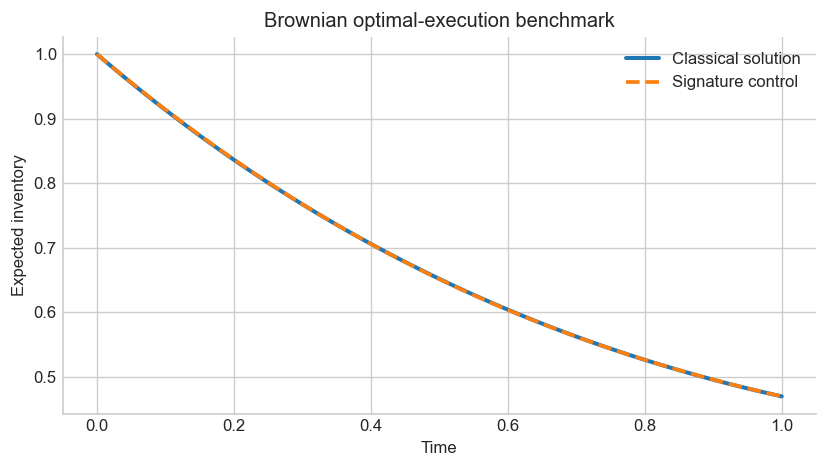

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(time, classical_inventory, linewidth=2.4, label="Classical solution")
ax.plot(time, signature_inventory, "--", linewidth=2.2, label="Signature control")
ax.set(title="Brownian optimal-execution benchmark", xlabel="Time", ylabel="Expected inventory")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "brownian_benchmark.png", bbox_inches="tight")
plt.show()

The signature strategy reproduces the shape of the classical liquidation curve. A ridge of $10^{-6}$ only resolves numerically flat signature directions; the optimizer reports curvature after this regularization instead of silently treating a stationary point as an optimum.

## 2. Minimum-energy liquidation sanity check

Before introducing a stochastic price term, consider

$$\min_\theta\;\mathbb E\left[\int_0^T\theta_t^2dt+N\left(q_0-\int_0^T\theta_tdt\right)^2\right].$$

The finite-penalty solution is the constant speed $\theta^*=Nq_0/(1+NT)$, which approaches uniform liquidation as $N\to\infty$. This is a direct check of the shuffle square and time-concatenation code.

In [6]:
energy_level = 3
energy_truncate = 2 * (energy_level + 1)
liquidation_penalty = 1000.0

energy_empty = st.SigPoly(2, energy_truncate, [1, 0, 0])
energy_time_letter = st.SigPoly(2, energy_truncate, [0, 1, 0])
energy_strategy = st.create_variable(2, energy_level, energy_truncate)
energy_inventory = q0 * energy_empty - energy_strategy.tensor(energy_time_letter)

effort = (energy_strategy * energy_strategy).tensor(energy_time_letter)
terminal_shortfall = energy_inventory * energy_inventory
energy_functional = effort + liquidation_penalty * terminal_shortfall
energy_expected_signature = st.expected_signature_time_augmented_brownian(
    sigma=sigma, T=T, level=energy_functional.level
)
energy_objective = energy_functional.inner(energy_expected_signature)
energy_solution = st.solve_quadratic_objective(
    energy_objective, sense="min", ridge=1e-6
)

energy_signature_inventory = expected_brownian_inventory(
    time, energy_solution.coefficients, energy_level, q0, sigma
)
constant_speed = liquidation_penalty * q0 / (1.0 + liquidation_penalty * T)
energy_closed_form = q0 - constant_speed * time
print(
    f"Regularized Hessian eigenvalues: [{energy_solution.min_eigenvalue:.3e}, "
    f"{energy_solution.max_eigenvalue:.3e}]"
)

Regularized Hessian eigenvalues: [1.476e-06, 2.562e+03]


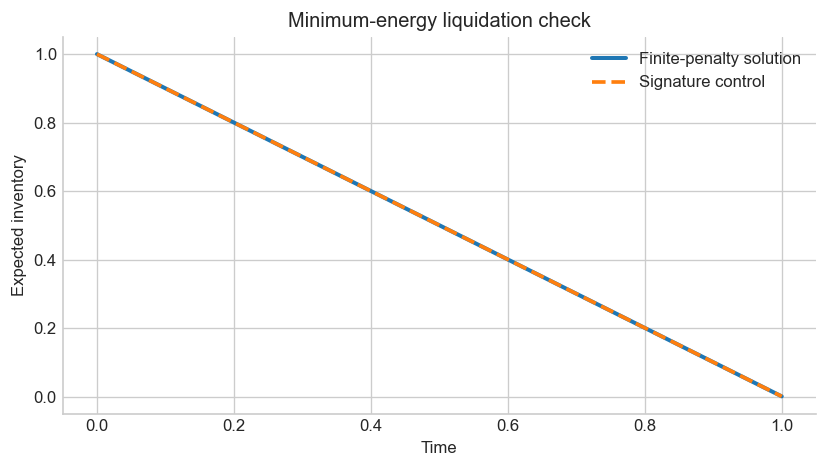

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(time, energy_closed_form, linewidth=2.4, label="Finite-penalty solution")
ax.plot(time, energy_signature_inventory, "--", linewidth=2.2, label="Signature control")
ax.set(title="Minimum-energy liquidation check", xlabel="Time", ylabel="Expected inventory")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "minimum_energy_check.png", bbox_inches="tight")
plt.show()

## 3. Geometric Brownian motion: alternative risk and price impact

For geometric Brownian motion, expected signatures are estimated from simulated paths. The baseline minimizes

$$\mathbb E\left[\int_0^T\left(\theta_t^2+\eta Q_tS_t\right)dt+NQ_T^2\right],$$

and the price-impact extension adds $\kappa^2Q_t^2$ inside the integral. Crucially, the empirical expected signature is computed through the maximum level required by both the running objective and the terminal square. Omitting the terminal square's last level can turn a positive quadratic form into an artificial saddle.

In [8]:
gbm_level = 3
gbm_truncate = 2 * gbm_level + 3
exposure_weight = 10.0
liquidation_penalty = 1000.0
kappa = 5.0
q0 = 1.0
S0 = 1.0
T = 1.0

gbm_paths = st.simulate_paths_geometric_brownian(
    m=1000, S0=S0, mu=0.0, sigma=1.0, seed=42, T=T, n=100
)
gbm_expected_signature = st.empirical_expected_signature(gbm_paths, gbm_truncate)


def solve_gbm_execution(inventory_cost):
    empty = st.SigPoly(2, gbm_truncate, [1, 0, 0])
    time_letter = st.SigPoly(2, gbm_truncate, [0, 1, 0])
    price_letter = st.SigPoly(2, gbm_truncate, [0, 0, 1])
    strategy = st.create_variable(2, gbm_level, gbm_truncate)
    inventory = q0 * empty - strategy.tensor(time_letter)
    price = S0 * empty + price_letter

    running_cost = strategy * strategy + exposure_weight * (inventory * price)
    if inventory_cost:
        running_cost = running_cost + inventory_cost**2 * (inventory * inventory)
    running_cost = running_cost.tensor(time_letter)
    terminal_cost = inventory * inventory

    required_level = max(running_cost.level, terminal_cost.level)
    assert required_level <= gbm_truncate
    objective = (
        running_cost.inner(gbm_expected_signature)
        + liquidation_penalty * terminal_cost.inner(gbm_expected_signature)
    )
    return st.solve_quadratic_objective(objective, sense="min", ridge=1e-6)


alternative_solution = solve_gbm_execution(inventory_cost=0.0)
impact_solution = solve_gbm_execution(inventory_cost=kappa)

print(
    "Alternative-risk Hessian: "
    f"[{alternative_solution.min_eigenvalue:.3e}, {alternative_solution.max_eigenvalue:.3e}]"
)
print(
    "Price-impact Hessian: "
    f"[{impact_solution.min_eigenvalue:.3e}, {impact_solution.max_eigenvalue:.3e}]"
)

Alternative-risk Hessian: [1.671e-05, 1.924e+05]
Price-impact Hessian: [2.074e-05, 1.927e+05]


In [9]:
comparison_paths = gbm_paths[:3]
gbm_time = comparison_paths[0, :, 0]
dt = gbm_time[1] - gbm_time[0]
prices = comparison_paths[:, :, 1]

alternative_inventory = signature_inventory_paths(
    comparison_paths, alternative_solution.coefficients, gbm_level, q0
)
impact_inventory = signature_inventory_paths(
    comparison_paths, impact_solution.coefficients, gbm_level, q0
)

integrated_price = cumulative_trapezoid(prices, dt)
alternative_closed_form = (1.0 - gbm_time[None, :] / T) * (
    q0 - (exposure_weight * T / 4.0) * integrated_price
)

kernel = prices / (1.0 + np.cosh(kappa * (T - gbm_time))[None, :])
integrated_kernel = cumulative_trapezoid(kernel, dt)
impact_closed_form = np.sinh(kappa * (T - gbm_time))[None, :] * (
    q0 / np.sinh(kappa * T)
    - exposure_weight * integrated_kernel / (2.0 * kappa)
)

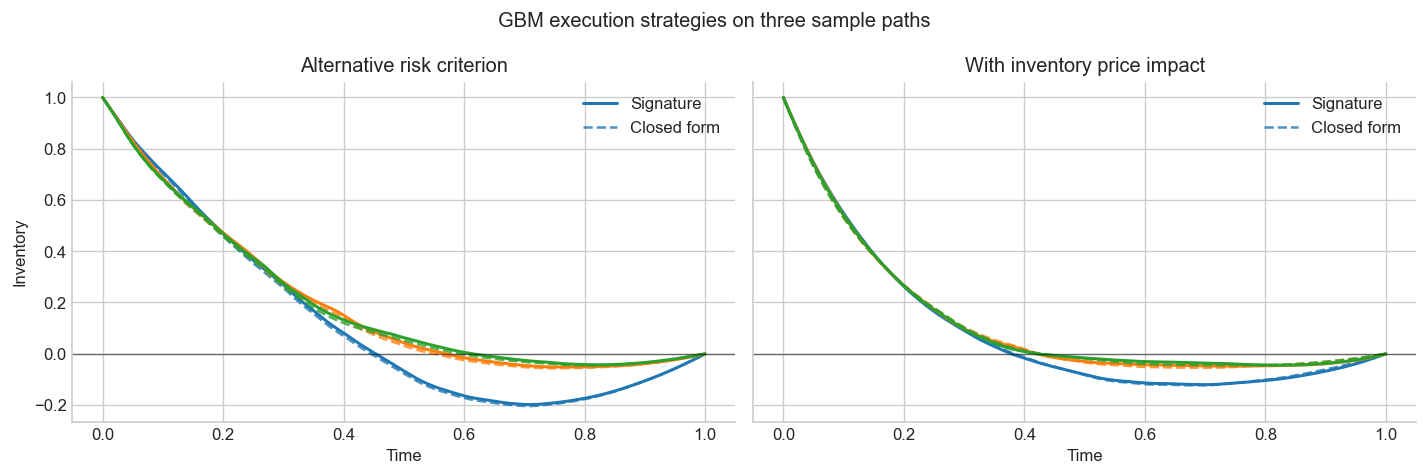

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
comparisons = [
    (axes[0], alternative_inventory, alternative_closed_form, "Alternative risk criterion"),
    (axes[1], impact_inventory, impact_closed_form, "With inventory price impact"),
]

for ax, signature_values, closed_form_values, title in comparisons:
    for path_index in range(comparison_paths.shape[0]):
        color = colors[path_index]
        ax.plot(
            gbm_time,
            signature_values[path_index],
            color=color,
            linewidth=1.8,
            label="Signature" if path_index == 0 else None,
        )
        ax.plot(
            gbm_time,
            closed_form_values[path_index],
            "--",
            color=color,
            linewidth=1.5,
            alpha=0.8,
            label="Closed form" if path_index == 0 else None,
        )
    ax.axhline(0.0, color="black", linewidth=0.8, alpha=0.5)
    ax.set(title=title, xlabel="Time")
    ax.legend()
axes[0].set_ylabel("Inventory")
fig.suptitle("GBM execution strategies on three sample paths")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "gbm_execution_comparison.png", bbox_inches="tight")
plt.show()

## Takeaways

- The custom algebra converts path-dependent controls into explicit quadratic objectives without a regression black box.
- Exact expected signatures give a clean Brownian benchmark; Monte Carlo expected signatures extend the same construction to GBM.
- Checking Hessian curvature is part of the algorithm. A stationary point is reported as an optimum only after convexity or concavity is verified.
- Approximation error comes from signature truncation, Monte Carlo estimation, the small numerical ridge, and the finite terminal-liquidation penalty.

The implementation follows the signature-control approach in [Kalsi, Lyons and Pérez Arribas (2019)](https://arxiv.org/abs/1905.00728). The GBM comparisons are motivated by [Gatheral and Schied's optimal-execution formulation](https://doi.org/10.1142/S0219024910005982).